# Proyecto 04: El Dominio de Fourier: Filtrado en la Frecuencia

## 0. Código y Funciones Auxiliares

In [1]:
# Import de librerías para la realización del proyecto

from pathlib import Path
from functools import reduce
from typing import Callable

import cv2
import numpy as np
import matplotlib.pyplot as plt

### 0.1 Carga de Imágenes

In [2]:
def load_images_dataset():
    """
    Función para cargar/leer las imágenes del dataset del proyecto. 
    Se cargan usando OpenCV y convertidas al formato a escala de grises.

    Devuelve tres listas, una con las imágenes cargadas, una 
    con los nombres de las imágenes y otra con el dominio 
    de frecuencias por FFT.
    """

    base_path = Path("./dataset")
    images = []
    filenames =  []
    ftts = []
    for path in base_path.iterdir():
        image = cv2.imread(path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        frequencies = np.fft.fft2(image.astype(float))
        frequencies = np.fft.fftshift(frequencies)
        images.append(image)
        filenames.append(path.name[-5])
        ftts.append(frequencies)
    return images, filenames, ftts

In [3]:
Path("./results").mkdir(exist_ok=True)
images, filenames, ffts = load_images_dataset()

### 0.2 Filtros de Butterworth y de Recorte

In [ ]:
def butterworth_band_reject_filter(
        img_size: tuple[int, int], 
        band_center: tuple[int, int] = (0, 0), 
        width: float = 1, 
        order: int = 2,
    ) -> np.ndarray:
    """
    Función para definir el filtro 
    de Butterworth rechaza banda con 
    los parámetros dados. Devuelve 
    una matriz que representa el 
    filtro.

    Toma de parámetros la forma de la 
    imagen, el centro de la banda, el 
    ancho y el orden. 
    """

    num_rows, num_cols = img_size
    rows = np.arange(-num_rows/2+1, num_rows/2+1)
    cols = np.arange(-num_cols/2+1, num_cols/2+1)
    frequencies_x, frequencies_y = np.meshgrid(rows, cols)

    distances = 1e-15+frequencies_x**2+frequencies_y**2
    distances = distances/distances.max()
    
    distances_center = 1e-15+(frequencies_x-band_center[0])**2+(frequencies_y-band_center[1])**2
    distances_center = distances_center/distances_center.max()

    score = (np.sqrt(distances)*width/distances_center)**(2*order)
    butterworth = 1/(1+score)
    return butterworth

def butterworth_low_pass_filter(
        img_size: tuple[int, int], 
        band_center: tuple[int, int] = (0, 0), 
        width: float = 1, 
        order: int = 2,
    ) -> np.ndarray:
    """
    Función para definir el filtro 
    de Butterworth pasa bajas (banda)
    con los parámetros dados. 
    Devuelve una matriz que representa 
    el filtro. 

    Toma de parámetros la forma de la 
    imagen, el centro de la banda, el 
    ancho y el orden.
    """

    butterworth = 1-butterworth_band_reject_filter(img_size, band_center, width, order)
    return butterworth

In [5]:
def single_notch_butterworth_filter(
        img_size: tuple[int, int], 
        band_center: tuple[int, int] = (0, 0), 
        width: float = 1, 
        order: int = 2,
    ) -> np.ndarray:
    """
    Función para definir un filtro de recorte 
    basado en los filtros de Butterworth con 
    los parámetros dados. Devuelve una matriz 
    que representa el filtro.

    Toma de parámetros la forma de la 
    imagen, el centro de la banda, el 
    ancho y el orden. 
    """

    butterworth_filter_1 = butterworth_band_reject_filter(img_size, band_center, width, order)
    butterworth_filter_2 = butterworth_band_reject_filter(img_size, (-band_center[0], -band_center[1]), width, order)
    notch_butterworth = butterworth_filter_1*butterworth_filter_2
    return notch_butterworth

In [6]:
def compose_notch_butterworth_filter(
        img_size: tuple[int, int],
        filter_parameters: list[tuple[tuple[int, int], float, int]]
    ) -> np.ndarray:
    """
    Función para definir el filtro de recorte 
    basándose en la composición (multiplicación) 
    de filtros simples de Butterworth pasa bajas. 
    Devuelve la matriz resultante de la composición.

    Toma de parámetros la forma de la imagen y 
    una lista con los parámetros de los filtros 
    como tuplas de (band_center, width, order).
    """

    simple_notch_filters = map(lambda params: single_notch_butterworth_filter(img_size, *params), filter_parameters)
    notch_butterworth = reduce(np.ndarray.__mul__, simple_notch_filters)
    return notch_butterworth

### 0.3 Visualización

In [7]:
def save_plot(
        create_plot: Callable[[np.ndarray, str], tuple[plt.Figure, str | None]]
    ) -> Callable:
    """
    Función para guardar un plot diseñado o 
    creado. Se espera que la función decorada 
    devuelva el objeto Figure y el nombre de 
    la figura.

    Devuelve el plot creado.
    """

    def saver(image: np.ndarray, *args, **kwargs) -> plt.Figure:
        fig, fig_name, *other_returns = create_plot(image, *args, **kwargs)
        if fig_name: fig.savefig(f"./results/{fig_name}.jpg", dpi=300, bbox_inches="tight")
        return fig, *other_returns
    
    return saver

In [8]:
@save_plot
def initial_description(
        image: np.ndarray, 
        fft_image: np.ndarray, 
        filename: str,
    ) -> tuple[plt.Figure, str]:
    """
    Función para graficar la imagen inicial 
    y su dominio de frecuencias. 
    Devuelve el plot generado.
    """

    fig, axes = plt.subplots(
        ncols = 2,
        subplot_kw = {
            "yticks": [],
            "xticks": [],
        },
        figsize = (8, 4),
    )
    axes: list[plt.Axes]

    axes[0].imshow(image, "gray")
    axes[0].set_title("Imagen Original")

    log_fft = np.log10(np.abs(fft_image))
    axes[1].imshow(255*log_fft/log_fft.max(), "gray")
    axes[1].set_title("Dominio de Frecuencias")
    
    fig.suptitle(f"Visualización Inicial de la Imagen {filename}")

    return fig, f"img_{filename}_initial"

In [9]:
@save_plot
def visualize_filter(
        fft_image: np.ndarray, 
        filter: np.ndarray,
        filename: str,
    ) -> tuple[plt.Figure, str]:
    """
    Función para graficar el efecto 
    del filtrado por frecuencias y 
    mostrar la imagen resultante. 
    Devuelve el plot generado
    """

    fig, axes = plt.subplots(
        ncols = 2,
        subplot_kw = {
            "yticks": [],
            "xticks": [],
        },
        figsize = (8, 4),
    )
    axes: list[plt.Axes]

    filter_fft = fft_image*filter
    log_fft = np.log1p(np.abs(filter_fft))
    axes[0].imshow(255*log_fft/log_fft.max(), "gray")
    axes[0].set_title("Dominio de Frecuencias Filtradas")

    filtered_img = np.fft.ifft2(filter_fft)
    filtered_img = np.abs(filtered_img).round().clip(0, 255)
    axes[1].imshow(filtered_img, "gray")
    axes[1].set_title("Imagen Resultante del Filtrado")
    
    fig.suptitle(f"Visualización la Imagen {filename} con Frecuencias Filtradas")

    return fig, f"img_{filename}_final", filtered_img

In [10]:
def apply_frequencies_filter(
        fft_image: np.ndarray, 
        filename: str,
        filter_parameters: list[tuple[tuple[int, int], float, int]]
    ) -> tuple[plt.Figure, np.ndarray]:
    """
    Función para aplicar filtrado de frecuencias 
    con filtros de Butterworth parametrizados 
    sobre el dominio de frecuencias de una imagen. 
    Devuelve el plot generado y la imagen resultante 
    del filtrado. 

    Toma de parámetros el dominio de frecuencias de 
    la imagen, su filename y las lista de parámetros 
    para la función `compose_notch_butterworth_filter`.
    """

    notch_butterworth_filter = compose_notch_butterworth_filter(
        fft_image.shape,
        filter_parameters
    )

    fig, filtered_image = visualize_filter(
        fft_image, 
        notch_butterworth_filter, 
        filename,
    )

    return fig, filtered_image

## Imagen 1

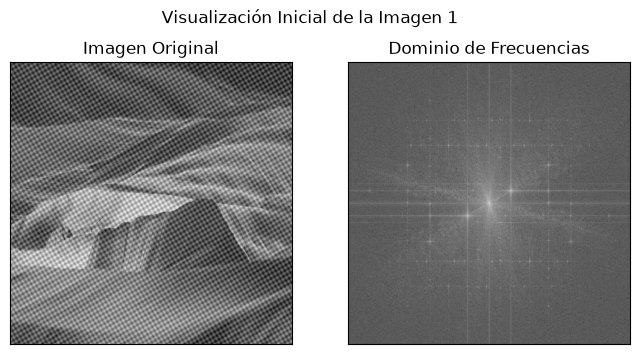

In [11]:
idx = 0
img_1 = images[idx]
name_1 = filenames[idx]
fft_1 = ffts[idx]

initial_description(img_1, fft_1, name_1);

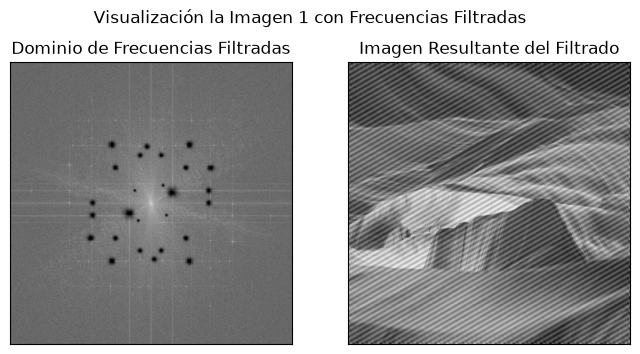

In [12]:
fig, filtered_img_1 = apply_frequencies_filter(
    fft_1,
    name_1,
    [
        ((60, -30), 0.01, 2),
        ((100, 100), 0.001, 2),
        ((100, -100), 0.001, 2),
        ((170, -100), 0.001, 2),
        ((110, 165), 0.001, 2),
        ((-110, 165), 0.001, 2),
        ((45, 35), 0.001, 2),
        ((35, -50), 0.001, 2),
        ((165, 0), 0.001, 2),
        ((165, -35), 0.001, 2),
        ((10, 160), 0.001, 2),
        ((30, 135), 0.001, 2),
        ((-30, 135), 0.001, 2),
    ]
);

### Experimento 1

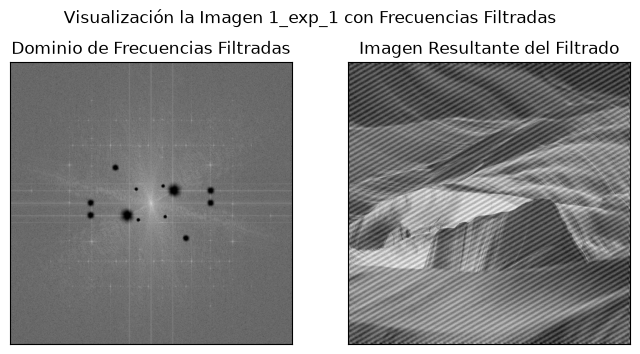

In [13]:
fig, filtered_img_1 = apply_frequencies_filter(
    fft_1,
    name_1+"_exp_1",
    [
        ((65, -35), 0.01, 3),
        ((100, 100), 0.001, 3),
        ((41, 39), 0.001, 4),
        ((35, -48), 0.001, 4),
        ((170, -35), 0.001, 3),
        ((170, 0), 0.001, 3),
    ]
);

## Imagen 2

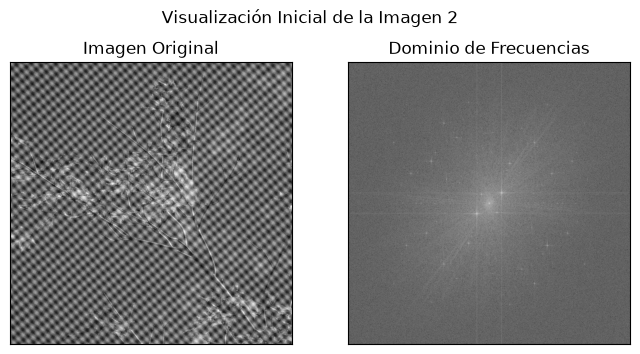

In [14]:
idx = 1
img_2 = images[idx]
name_2 = filenames[idx]
fft_2 = ffts[idx]

initial_description(img_2, fft_2, name_2);

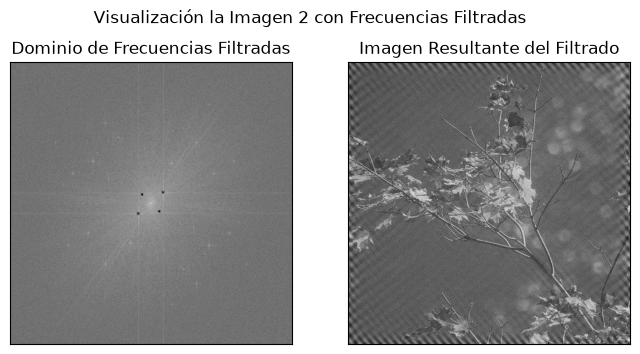

In [15]:
fig, filtered_img_2 = apply_frequencies_filter(
    fft_2,
    name_2,
    [
        ((24, 24), 0.001, 3),
        ((35, -30), 0.0013, 2),
    ]
);

### Experimento 1

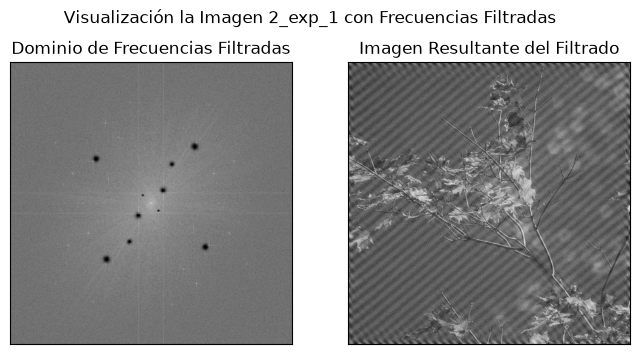

In [16]:
fig, filtered_img_2 = apply_frequencies_filter(
    fft_2,
    name_2+"_exp_1",
    [
        ((22, 22), 0.0012, 2),
        ((35, -35), 0.005, 2),
        ((60, -110), 0.001, 2),
        ((125, -160), 0.001, 2),
        ((-155, -125), 0.0008, 2),
    ]
);

## Imagen 3

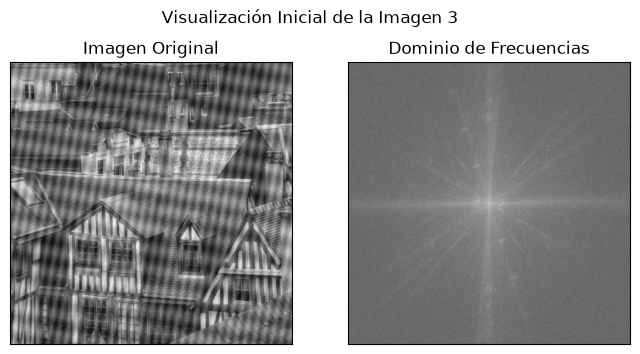

In [17]:
idx = 2
img_3 = images[idx]
name_3 = filenames[idx]
fft_3 = ffts[idx]

initial_description(img_3, fft_3, name_3);

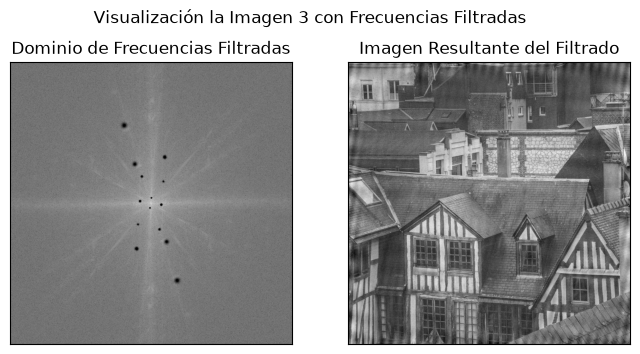

In [18]:
fig, filtered_img_3 = apply_frequencies_filter(
    fft_3,
    name_3,
    [
        ((30, 5), 0.0013, 5),
        ((-2, 14), 0.0013, 5),
        ((-36, 61), 0.0005, 2),
        ((25, 75), 0.0005, 3),
        ((-40, 130), 0.0005, 3),
        ((45, 110), 0.001, 2),
        ((75, 220), 0.0005, 2),
    ]
);

### Experimento 1

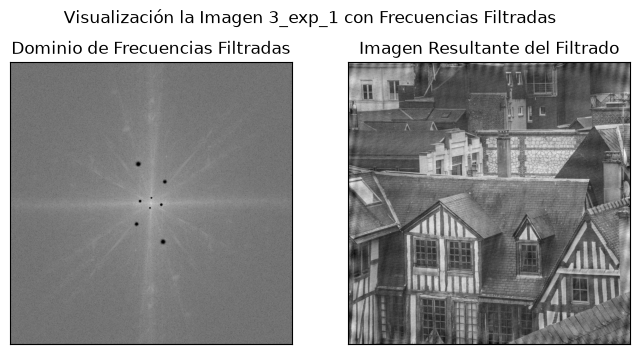

In [19]:
fig, filtered_img_3 = apply_frequencies_filter(
    fft_3,
    name_3+"_exp_1",
    [
        ((30, 5), 0.0013, 5),
        ((-2, 14), 0.0013, 5),
        ((35, 110), 0.001, 3),
        ((40, -60), 0.001, 3),
    ]
);

## Imagen 4

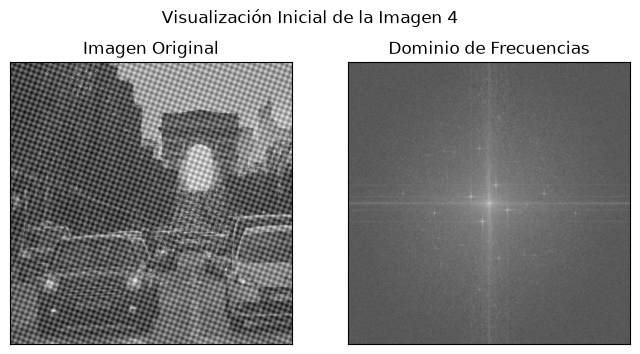

In [20]:
idx = 3
img_4 = images[idx]
name_4 = filenames[idx]
fft_4 = ffts[idx]

initial_description(img_4, fft_4, name_4);

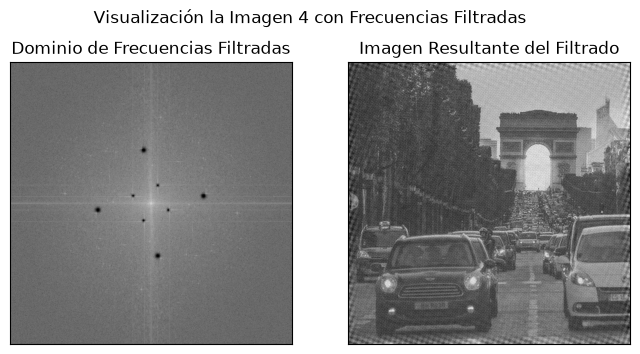

In [21]:
fig, filtered_img_4 = apply_frequencies_filter(
    fft_4,
    name_4,
    [
        ((50, 20), 0.0015, 2),
        ((-20, 50), 0.0015, 2),
        ((20, 150), 0.001, 2),
        ((150, -20), 0.001, 2),
    ]
);

## Imagen 5

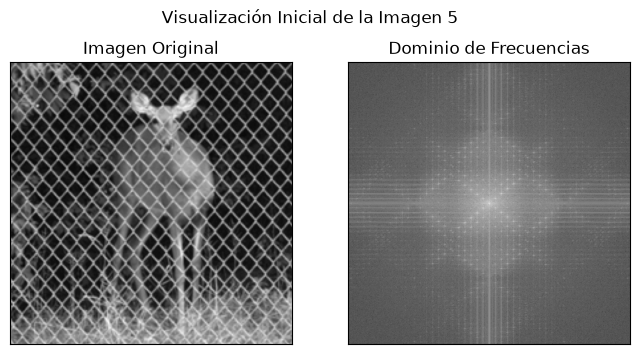

In [22]:
idx = 4
img_5 = images[idx]
name_5 = filenames[idx]
fft_5 = ffts[idx]

initial_description(img_5, fft_5, name_5);

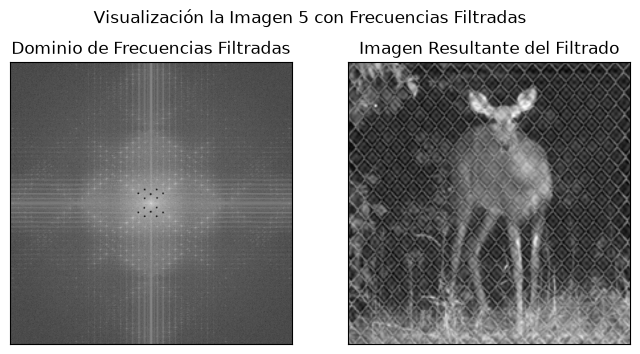

In [23]:
fig, filtered_img_5 = apply_frequencies_filter(
    fft_5,
    name_5,
    [
        ((18, -14), 0.001, 3),
        ((17, 13), 0.001, 3),
        ((0, 25), 0.001, 3),
        ((35, -27), 0.0005, 3),
        ((35, 27), 0.0005, 3),
        ((17, -38), 0.0005, 3),
        ((17, 38), 0.0005, 3),
    ]
);

### Experimento 1

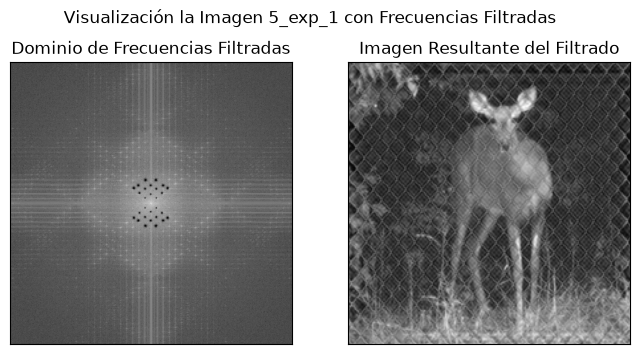

In [24]:
fig, filtered_img_5 = apply_frequencies_filter(
    fft_5,
    name_5+"_exp_1",
    [
        ((16, -14), 0.001, 2),
        ((32, -28), 0.001, 2),
        ((48, -42), 0.001, 2),
        ((16, 14), 0.001, 2),
        ((32, 28), 0.001, 2),
        ((48, 42), 0.001, 2),
        ((0, 25), 0.001, 2),
        ((0, 50), 0.001, 2),
        ((16, -40), 0.001, 2),
        ((16, 40), 0.001, 2),
        ((35, -50), 0.001, 2),
        ((35, 50), 0.001, 2),
        ((15, 65), 0.001, 2),
        ((15, -65), 0.001, 2),
    ]
);